# Modelagem MLP — Veículos Furtados x Roubados (São Paulo, capital)

**Objetivo:** prever se uma ocorrência de veículo é **Furtado (0)** ou **Roubado (1)** com uma rede neural *Multilayer Perceptron*.

Este notebook cobre a **Fase 2** (engenharia de features, split, encoders/scalers, tensores e setup da rede) e a **Fase 3** (treinamento, comparação de três arquiteturas e exportação do melhor modelo).

As funções de transformação vivem em `src/data_prep.py` para serem reutilizadas pela aplicação Streamlit.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import data_prep as dp
from src.architecture import MLP

SEED = dp.RANDOM_STATE
np.random.seed(SEED)
torch.manual_seed(SEED)
print("torch", torch.__version__)

torch 2.15.0


## 1. Carga da amostra de 15k (saída da Fase 1)

In [2]:
raw = pd.read_csv(dp.PROCESSED_PATH)
print(raw.shape)
raw[dp.TARGET_COL].value_counts(normalize=True).rename({0: "Furtado (0)", 1: "Roubado (1)"}).round(4)

(15000, 35)


ALVO
Furtado (0)    0.8331
Roubado (1)    0.1669
Name: proportion, dtype: float64

## 2. Engenharia de features (transformações sem estado)

`build_features` aplica, linha a linha:

- **Remoção de vazamento administrativo:** colunas da delegacia de *registro* ficam de fora; só entram as de circunscrição do fato.
- **`PERIODO_FATO`:** hora → Madrugada (0–5), Manhã (6–11), Tarde (12–17), Noite (18–23); sem hora, usa `DESCR_PERIODO`; o que sobra vira `Incerto`.
- **`MARCA_VEICULO`:** marca principal extraída de `DESCR_MARCA_VEICULO` (remove prefixo de importado `I/`, unifica `GM`/`CHEV` → `CHEVROLET` etc.).
- **Coordenadas:** valores fora do município (ex.: `0, 0`) viram nulos para imputação.
- **`IDADE_VEICULO`:** `ANO_BO` − ano do veículo.
- **Ruído removido:** constantes, quase constantes, `DESC_NATUREZA_LOCAL`, `LOGRADOURO_VERSAO`, `CEP`, `CMD` e o alvo textual.

In [3]:
feats = dp.build_features(raw)
print(feats.shape)
feats.head()

(15000, 15)


,NOME_SECCIONAL_CIRC,NOME_DELEGACIA_CIRC,BTL,CIA,DESCR_TIPOLOCAL,DESCR_SUBTIPOLOCAL,DESCR_TIPO_VEICULO,DESCR_COR_VEICULO,BAIRRO,PERIODO_FATO,MARCA_VEICULO,LATITUDE,LONGITUDE,IDADE_VEICULO,ALVO
0,DEL.SEC.6º SANTO AMARO,80º D.P. VILA JOANIZA,22ºBPM/M,4ªCIA,Comércio e Serviços,Mercado,Automovel,Branco,JARDIM SANTA CRUZ (CAMPO GRANDE),Manhã,FIAT,-23.682518,-46.676091,25.0,0
1,DEL.SEC.2º SUL,17º D.P. DOUTOR ALDO GALIANO,46ºBPM/M,2ªCIA,Via Pública,Via Pública,Automovel,Preta,IPIRANGA,Incerto,VW,-23.595581,-46.597557,17.0,0
2,DEL.SEC.8º SAO MATEUS,54º D.P. CID. TIRADENTES,28ºBPM/M,3ªCIA,Via Pública,Via Pública,Motociclo,Preta,GUAIANASES,Madrugada,TVS,-23.610155,-46.407821,3.0,0
3,DEL.SEC.4º NORTE,09º D.P. - CARANDIRU,5ºBPM/M,4ªCIA,Via Pública,Via Pública,Automovel,Cinza,SANTANA,Tarde,HONDA,-23.493883,-46.616114,18.0,0
4,DEL.SEC.1º CENTRO,78º D.P. JARDINS,11ºBPM/M,3ªCIA,Via Pública,Via Pública,Motociclo,Prata,JARDIM PAULISTA,Noite,HONDA,-23.559349,-46.668699,4.0,0


### Por que não há flag de `ANO_MODELO` nulo

A ausência de `ANO_MODELO` é praticamente um espelho do canal de registro: quase todo BO da Delegacia Eletrônica vem sem esse campo. Uma flag de nulo (ou uma idade imputada pela mediana em 62% das linhas) devolveria ao modelo o vazamento que foi removido. Por isso a idade usa `ANO_FABRICACAO`, preenchido em 99,4% das linhas. A especificação literal pode ser ligada com `dp.USE_ANO_MODELO_FLAG = True`.

In [4]:
eletronica = raw["NOME_DELEGACIA"].eq("DELEGACIA ELETRONICA").rename("registrado_na_delegacia_eletronica")
ano_modelo_nulo = raw["ANO_MODELO"].isna().rename("ANO_MODELO_nulo")
display(pd.crosstab(eletronica, ano_modelo_nulo))
raw.groupby(ano_modelo_nulo)[dp.TARGET_COL].agg(taxa_roubo="mean", n="size").round(3)

ANO_MODELO_nulo,False,True
registrado_na_delegacia_eletronica,,
False,5671,99
True,16,9214


,taxa_roubo,n
ANO_MODELO_nulo,,
False,0.264,5687
True,0.108,9313


In [5]:
feats["PERIODO_FATO"].value_counts()

PERIODO_FATO
Noite        5235
Tarde        4025
Manhã        3275
Madrugada    2217
Incerto       248
Name: count, dtype: int64

## 3. Split estratificado 70 / 15 / 15

O split vem **antes** de qualquer estatística aprendida (Top-20, medianas, encoder, scaler), para que validação e teste não influenciem o pré-processamento.

In [6]:
train_df, val_df, test_df = dp.split_data(feats)
pd.DataFrame({
    nome: {"linhas": len(d), "taxa_roubo": round(d[dp.TARGET_COL].mean(), 4)}
    for nome, d in [("treino", train_df), ("validação", val_df), ("teste", test_df)]
}).T

,linhas,taxa_roubo
treino,10500.0,0.1670
validação,2250.0,0.1671
teste,2250.0,0.1667


## 4. Top-20 + `OUTROS` e imputação (ajustados só no treino)

- `BAIRRO`, `MARCA_VEICULO` e `NOME_DELEGACIA_CIRC`: Top-20 do treino, restante em `OUTROS`.
- `LATITUDE`/`LONGITUDE`: mediana do bairro; se o bairro for `OUTROS`, mediana da cidade.
- `IDADE_VEICULO`: mediana do treino.

In [7]:
meta = dp.fit_preprocessor(train_df)
train_p, val_p, test_p = (dp.apply_preprocessor(d, meta) for d in (train_df, val_df, test_df))

print("Mediana de idade (treino):", meta["idade_median"])
print("Nulos restantes:", int(train_p.isna().sum().sum() + val_p.isna().sum().sum() + test_p.isna().sum().sum()))
train_p[dp.CATEGORICAL_COLS].nunique().rename("categorias no treino")

Mediana de idade (treino): 6.0


Nulos restantes: 0


NOME_SECCIONAL_CIRC     8
NOME_DELEGACIA_CIRC    21
BTL                    27
CIA                    10
PERIODO_FATO            5
DESCR_TIPOLOCAL        21
DESCR_SUBTIPOLOCAL     50
BAIRRO                 21
DESCR_TIPO_VEICULO     16
MARCA_VEICULO          21
DESCR_COR_VEICULO      15
Name: categorias no treino, dtype: int64

## 5. One-Hot Encoder + StandardScaler (ajustados só no treino) e persistência

In [8]:
encoder, scaler = dp.fit_transformers(train_p, meta)

X_train = dp.transform_features(train_p, meta, encoder, scaler)
X_val = dp.transform_features(val_p, meta, encoder, scaler)
X_test = dp.transform_features(test_p, meta, encoder, scaler)
y_train, y_val, y_test = (d[dp.TARGET_COL].to_numpy(dtype=np.float32) for d in (train_p, val_p, test_p))

FEATURE_NAMES = dp.feature_names(meta, encoder)
dp.save_artifacts(encoder, scaler, meta)
print("Artefatos salvos:", sorted(p.name for p in dp.MODELS_DIR.glob("*.pkl")))
print("X_train", X_train.shape, "| X_val", X_val.shape, "| X_test", X_test.shape)

Artefatos salvos: ['encoder.pkl', 'preprocess_meta.pkl', 'scaler.pkl']
X_train (10500, 218) | X_val (2250, 218) | X_test (2250, 218)


## 6. Tensores PyTorch

In [9]:
X_train_t, X_val_t, X_test_t = (torch.from_numpy(x) for x in (X_train, X_val, X_test))
y_train_t, y_val_t, y_test_t = (torch.from_numpy(y) for y in (y_train, y_val, y_test))

INPUT_DIM = X_train_t.shape[1]
for nome, x, y in [("treino", X_train_t, y_train_t), ("validação", X_val_t, y_val_t), ("teste", X_test_t, y_test_t)]:
    print(f"{nome:10s} X={tuple(x.shape)} {x.dtype} | y={tuple(y.shape)} {y.dtype}")
print("INPUT_DIM =", INPUT_DIM)

treino     X=(10500, 218) torch.float32 | y=(10500,) torch.float32
validação  X=(2250, 218) torch.float32 | y=(2250,) torch.float32
teste      X=(2250, 218) torch.float32 | y=(2250,) torch.float32
INPUT_DIM = 218


## 7. Pesos de classe

Com ~83% de furtos, a perda sem peso favorece a classe majoritária. `pos_weight = n_negativos / n_positivos` (calculado no treino) faz cada roubo pesar proporcionalmente mais na `BCEWithLogitsLoss`.

In [10]:
n_pos = int(y_train.sum())
n_neg = int(len(y_train) - n_pos)
POS_WEIGHT = torch.tensor(n_neg / n_pos, dtype=torch.float32)
CLASS_WEIGHTS = {0: len(y_train) / (2 * n_neg), 1: len(y_train) / (2 * n_pos)}  # equivalente ao "balanced" do sklearn

criterion = torch.nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)
print(f"Furtado (0): {n_neg} | Roubado (1): {n_pos}")
print(f"POS_WEIGHT = {POS_WEIGHT.item():.4f}")
print("CLASS_WEIGHTS =", {k: round(v, 4) for k, v in CLASS_WEIGHTS.items()})

Furtado (0): 8747 | Roubado (1): 1753
POS_WEIGHT = 4.9897
CLASS_WEIGHTS = {0: 0.6002, 1: 2.9949}


## 8. Setup da rede (`src/architecture.py`)

`MLP` recebe `hidden_dims` (profundidade e largura), `dropout`, `activation` e `batch_norm`. Abaixo, apenas um teste de sanidade da classe — o treinamento é a Fase 3.

In [11]:
model = MLP(input_dim=INPUT_DIM, hidden_dims=(64, 32), dropout=0.3)
print(model)
print("Parâmetros treináveis:", model.n_parameters())

model.eval()
with torch.no_grad():
    logits = model(X_train_t[:8])
print("Shape dos logits:", tuple(logits.shape), "| loss inicial:", round(criterion(logits, y_train_t[:8]).item(), 4))

MLP(
  (hidden): Sequential(
    (0): Linear(in_features=218, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
  )
  (output): Linear(in_features=32, out_features=1, bias=True)
)
Parâmetros treináveis: 16321
Shape dos logits: (8,) | loss inicial: 1.4015


# Fase 3 — Treinamento e experimentação

## 9. Configuração de treino

- **Otimizador:** Adam, `lr = 1e-3`.
- **Perda:** `BCEWithLogitsLoss(pos_weight=POS_WEIGHT)`, compensando o desbalanceamento 83/17.
- **Batch size:** 128.
- **Early stopping:** monitora `val_loss` com paciência de 15 épocas e **restaura os pesos da melhor época**.
- **Limiar de decisão:** 0,5 sobre a probabilidade (sigmoid do logit).

As três arquiteturas variam profundidade, largura, dropout e uso de BatchNorm; todo o resto é mantido fixo para que a comparação seja justa.

In [12]:
import copy
import time

import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from torch.utils.data import DataLoader, TensorDataset

BATCH_SIZE = 128
LEARNING_RATE = 1e-3
MAX_EPOCHS = 200
PATIENCE = 15
THRESHOLD = 0.5
CLASS_NAMES = ["Furtado", "Roubado"]

ARCHITECTURES = {
    "Arq. 1 - Baseline (64)": dict(hidden_dims=(64,), batch_norm=False, dropout=0.1),
    "Arq. 2 - Intermediária (128, 64)": dict(hidden_dims=(128, 64), batch_norm=True, dropout=0.3),
    "Arq. 3 - Profunda (256, 128, 64)": dict(hidden_dims=(256, 128, 64), batch_norm=True, dropout=0.4),
}

In [13]:
def compute_metrics(y_true, probs, threshold=THRESHOLD) -> dict:
    y_pred = (np.asarray(probs) >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


@torch.no_grad()
def evaluate(model, X, y):
    """Perda e probabilidades em modo de avaliação (sem dropout)."""
    model.eval()
    logits = model(X)
    return criterion(logits, y).item(), torch.sigmoid(logits).numpy()


def train_model(config: dict):
    torch.manual_seed(SEED)
    model = MLP(input_dim=INPUT_DIM, **config)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))

    history, best_loss, best_state, best_epoch, wait = [], float("inf"), None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()

        train_loss, train_probs = evaluate(model, X_train_t, y_train_t)
        val_loss, val_probs = evaluate(model, X_val_t, y_val_t)
        train_m, val_m = compute_metrics(y_train, train_probs), compute_metrics(y_val, val_probs)
        history.append({
            "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
            "train_acc": train_m["accuracy"], "val_acc": val_m["accuracy"],
            "train_f1": train_m["f1_macro"], "val_f1": val_m["f1_macro"],
        })

        if val_loss < best_loss - 1e-4:
            best_loss, best_epoch, wait = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch

## 10. Treinamento das três arquiteturas

In [14]:
results = {}
for name, config in ARCHITECTURES.items():
    start = time.time()
    model, history, best_epoch = train_model(config)
    results[name] = {"model": model, "history": history, "best_epoch": best_epoch}
    best = history.loc[best_epoch - 1]
    print(f"{name:34s} | params={model.n_parameters():>7,d} | épocas={len(history):3d} | melhor época={best_epoch:3d} "
          f"| val_loss={best.val_loss:.4f} | val_f1_macro={best.val_f1:.4f} | {time.time() - start:.1f}s")

Arq. 1 - Baseline (64)             | params= 14,081 | épocas= 31 | melhor época= 16 | val_loss=0.7720 | val_f1_macro=0.7290 | 1.9s


Arq. 2 - Intermediária (128, 64)   | params= 36,737 | épocas= 19 | melhor época=  4 | val_loss=0.7628 | val_f1_macro=0.7161 | 1.3s


Arq. 3 - Profunda (256, 128, 64)   | params= 98,177 | épocas= 19 | melhor época=  4 | val_loss=0.7635 | val_f1_macro=0.7072 | 2.0s


## 11. Curvas de aprendizado (treino vs validação)

A linha tracejada marca a época com menor `val_loss`, cujos pesos foram restaurados. Curvas de treino e validação se afastando depois dessa linha indicam *overfitting*.

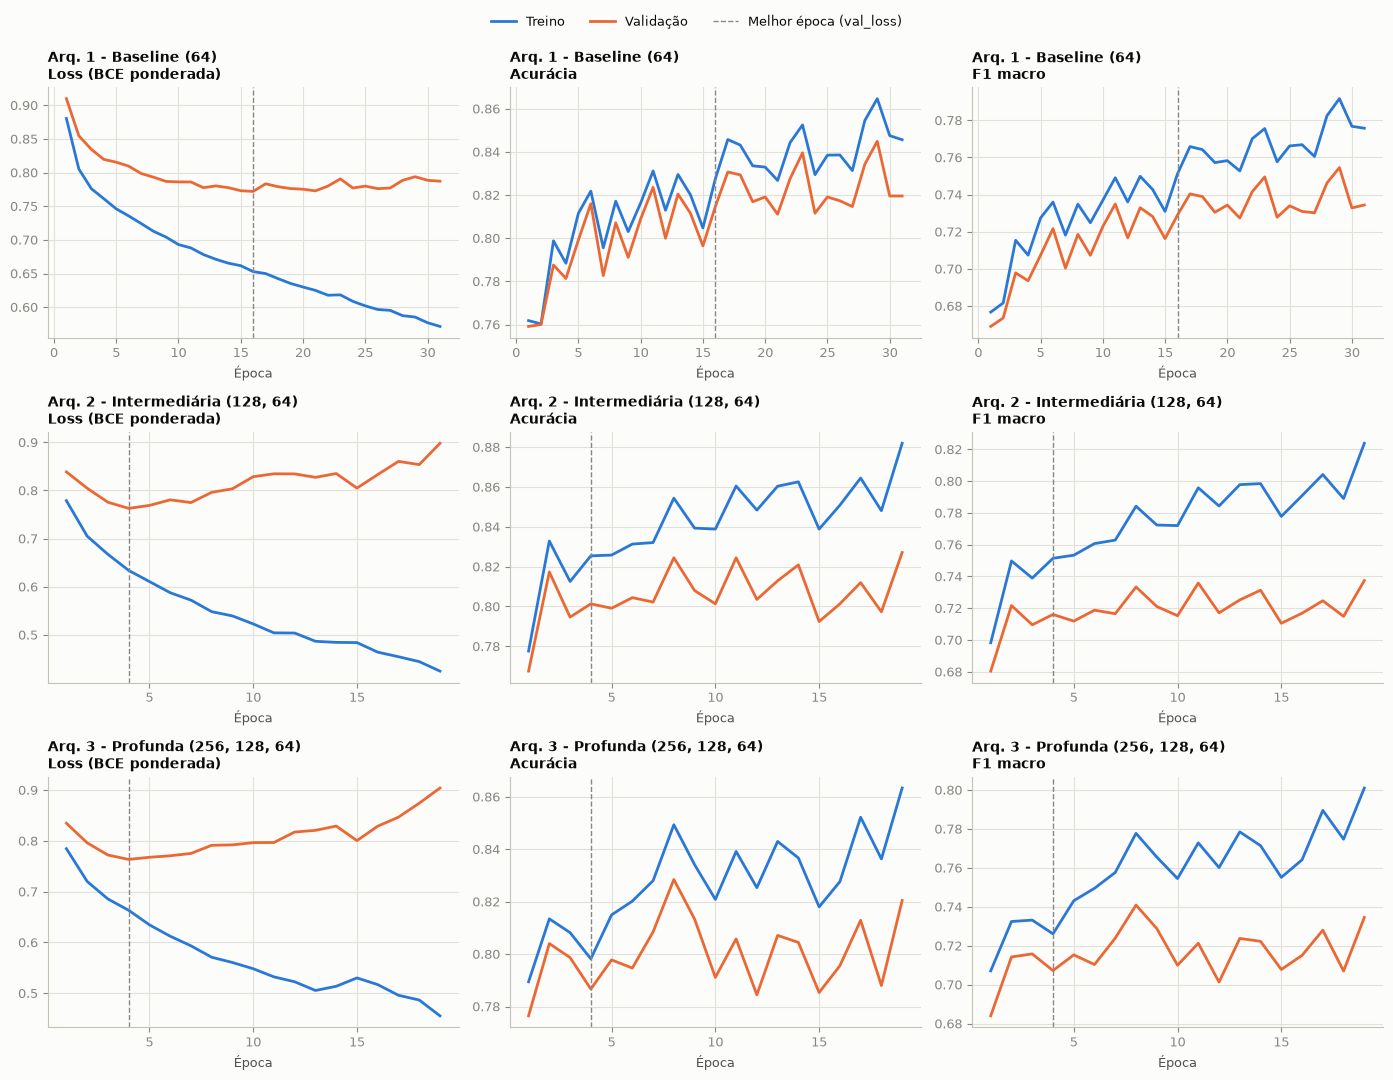

In [15]:
TRAIN_COLOR, VAL_COLOR = "#2a78d6", "#eb6834"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlesize": 10, "axes.titleweight": "bold", "font.size": 9,
})

panels = [("loss", "Loss (BCE ponderada)"), ("acc", "Acurácia"), ("f1", "F1 macro")]
fig, axes = plt.subplots(len(results), 3, figsize=(14, 3.6 * len(results)), sharex="row")
for row, (name, res) in zip(axes, results.items()):
    h = res["history"]
    for ax, (key, label) in zip(row, panels):
        ax.plot(h["epoch"], h[f"train_{key}"], color=TRAIN_COLOR, linewidth=2, label="Treino")
        ax.plot(h["epoch"], h[f"val_{key}"], color=VAL_COLOR, linewidth=2, label="Validação")
        ax.axvline(res["best_epoch"], color=MUTED, linestyle="--", linewidth=1, label="Melhor época (val_loss)")
        ax.set_title(f"{name}\n{label}", loc="left")
        ax.set_xlabel("Época")
        ax.xaxis.get_major_locator().set_params(integer=True)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

In [16]:
# Diagnóstico numérico: distância treino-validação na melhor época e na última época treinada.
diag = []
for name, res in results.items():
    h = res["history"]
    best, last = h.loc[res["best_epoch"] - 1], h.iloc[-1]
    diag.append({
        "arquitetura": name, "melhor_época": res["best_epoch"], "épocas_treinadas": len(h),
        "train_loss (melhor)": best.train_loss, "val_loss (melhor)": best.val_loss,
        "gap F1 treino-val (melhor)": best.train_f1 - best.val_f1,
        "gap F1 treino-val (última)": last.train_f1 - last.val_f1,
    })
pd.DataFrame(diag).set_index("arquitetura").round(4)

,melhor_época,épocas_treinadas,train_loss (melhor),val_loss (melhor),gap F1 treino-val (melhor),gap F1 treino-val (última)
arquitetura,,,,,,
Arq. 1 - Baseline (64),16,31,0.6528,0.7720,0.0222,0.0413
"Arq. 2 - Intermediária (128, 64)",4,19,0.6339,0.7628,0.0354,0.0864
"Arq. 3 - Profunda (256, 128, 64)",4,19,0.6633,0.7635,0.0189,0.0665


## 12. Seleção do modelo e avaliação no teste

O vencedor é escolhido pelo **F1 macro de validação**. O conjunto de teste não participa da escolha — ele só mede o desempenho final, para que a estimativa não fique otimista.

In [17]:
def metrics_table(X, y) -> pd.DataFrame:
    rows = {}
    for name, res in results.items():
        _, probs = evaluate(res["model"], torch.from_numpy(X), torch.from_numpy(y))
        res_metrics = compute_metrics(y, probs)
        rows[name] = {"Acurácia": res_metrics["accuracy"], "Precision (macro)": res_metrics["precision_macro"],
                      "Recall (macro)": res_metrics["recall_macro"], "F1 (macro)": res_metrics["f1_macro"]}
    return pd.DataFrame(rows).T

val_table = metrics_table(X_val, y_val)
BEST_NAME = val_table["F1 (macro)"].idxmax()
best_model = results[BEST_NAME]["model"]
print("Validação:")
display(val_table.round(4))
print("Vencedor (maior F1 macro na validação):", BEST_NAME)

Validação:


,Acurácia,Precision (macro),Recall (macro),F1 (macro)
Arq. 1 - Baseline (64),0.8147,0.7051,0.7909,0.7290
"Arq. 2 - Intermediária (128, 64)",0.8013,0.6940,0.7840,0.7161
"Arq. 3 - Profunda (256, 128, 64)",0.7867,0.6881,0.7901,0.7072


Vencedor (maior F1 macro na validação): Arq. 1 - Baseline (64)


In [18]:
test_table = metrics_table(X_test, y_test)
test_table["Parâmetros"] = [results[n]["model"].n_parameters() for n in test_table.index]
test_table["Melhor época"] = [results[n]["best_epoch"] for n in test_table.index]
print("Tabela comparativa - conjunto de TESTE (limiar 0,5):")
test_table.round(4)

Tabela comparativa - conjunto de TESTE (limiar 0,5):


,Acurácia,Precision (macro),Recall (macro),F1 (macro),Parâmetros,Melhor época
Arq. 1 - Baseline (64),0.8320,0.7246,0.8139,0.7512,14081,16
"Arq. 2 - Intermediária (128, 64)",0.8191,0.7161,0.8179,0.7418,36737,4
"Arq. 3 - Profunda (256, 128, 64)",0.7920,0.6962,0.8059,0.7163,98177,4


In [19]:
# Referência: classificador que sempre prevê a classe majoritária (Furtado).
baseline_pred = np.zeros_like(y_test)
print(f"Sempre 'Furtado' -> acurácia={accuracy_score(y_test, baseline_pred):.4f} | "
      f"F1 macro={f1_score(y_test, baseline_pred, average='macro'):.4f}")

Sempre 'Furtado' -> acurácia=0.8333 | F1 macro=0.4545


**Leitura dos resultados**

- **A rede mais simples venceu.** A Arq. 1 tem o maior F1 macro na validação e no teste; aumentar profundidade e largura não trouxe ganho, só mais parâmetros para memorizar o treino.
- **Overfitting nas redes maiores.** As Arq. 2 e 3 atingem a menor `val_loss` já na época 4; a partir daí a perda de treino continua caindo enquanto a de validação sobe. O early stopping restaurou os pesos da época 4 em ambas. Na Arq. 1 a divergência é bem mais lenta (melhor época 16).
- **Acurácia engana neste problema.** Prever sempre "Furtado" dá ~83% de acurácia com F1 macro de 0,45. Os modelos têm acurácia parecida com essa, mas recuperam cerca de 80% dos roubos — por isso a comparação é feita por F1 macro.
- **Custo do `pos_weight`:** o recall de roubo é alto, mas a precisão de roubo fica perto de 50% (há muitos furtos classificados como roubo). A seção 14 mostra como o limiar de decisão ajusta esse equilíbrio.

## 13. Matrizes de confusão (teste)

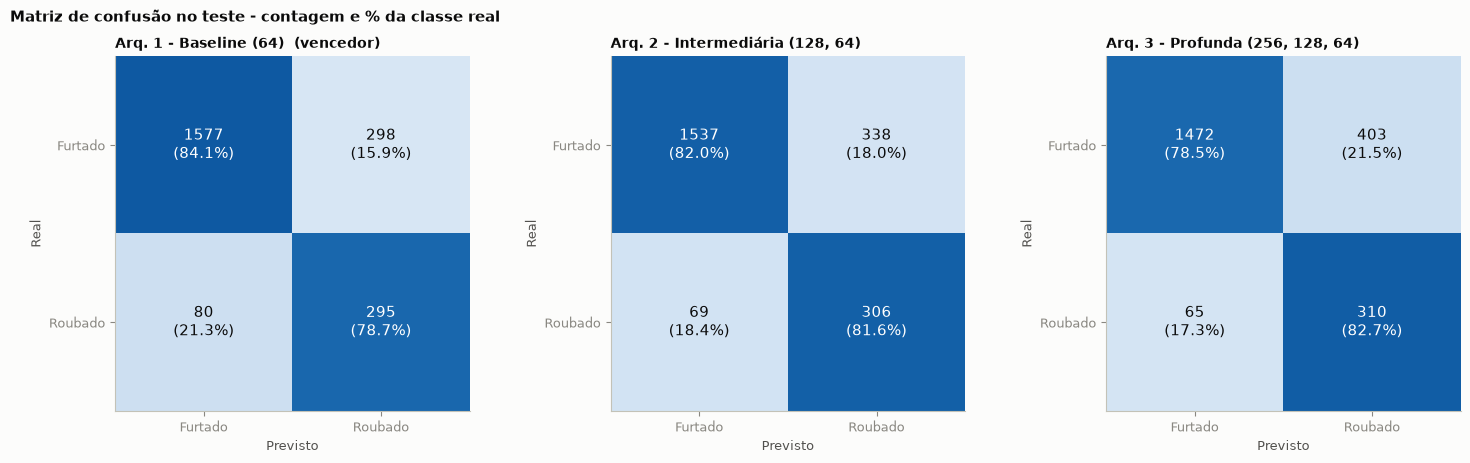

In [20]:
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4.6))
for ax, (name, res) in zip(axes, results.items()):
    _, probs = evaluate(res["model"], X_test_t, y_test_t)
    cm = confusion_matrix(y_test, (probs >= THRESHOLD).astype(int))
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({pct[i, j]:.1%})", ha="center", va="center",
                    color="white" if pct[i, j] > 0.55 else INK, fontsize=11)
    ax.set_xticks([0, 1], CLASS_NAMES)
    ax.set_yticks([0, 1], CLASS_NAMES)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
    ax.grid(False)
    ax.set_title(name + ("  (vencedor)" if name == BEST_NAME else ""), loc="left")
fig.suptitle("Matriz de confusão no teste - contagem e % da classe real", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [21]:
_, best_test_probs = evaluate(best_model, X_test_t, y_test_t)
print(BEST_NAME, "- relatório por classe no teste (limiar 0,5)\n")
print(classification_report(y_test, (best_test_probs >= THRESHOLD).astype(int), target_names=CLASS_NAMES, digits=4))

Arq. 1 - Baseline (64) - relatório por classe no teste (limiar 0,5)

              precision    recall  f1-score   support

     Furtado     0.9517    0.8411    0.8930      1875
     Roubado     0.4975    0.7867    0.6095       375

    accuracy                         0.8320      2250
   macro avg     0.7246    0.8139    0.7512      2250
weighted avg     0.8760    0.8320    0.8457      2250



## 14. Limiar de decisão do vencedor

Com `pos_weight`, as probabilidades ficam deslocadas para cima e o limiar 0,5 não é necessariamente o melhor. Abaixo, o limiar que maximiza o F1 macro **na validação** é comparado ao 0,5 no teste.

In [22]:
_, best_val_probs = evaluate(best_model, X_val_t, y_val_t)
grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
val_f1_by_threshold = pd.Series([compute_metrics(y_val, best_val_probs, t)["f1_macro"] for t in grid], index=grid)
BEST_THRESHOLD = float(val_f1_by_threshold.idxmax())

threshold_table = pd.DataFrame({
    "limiar 0,50": compute_metrics(y_test, best_test_probs, 0.5),
    f"limiar {BEST_THRESHOLD:.2f} (ótimo na validação)": compute_metrics(y_test, best_test_probs, BEST_THRESHOLD),
}).T
print(f"Limiar ótimo na validação: {BEST_THRESHOLD:.2f} (F1 macro val = {val_f1_by_threshold.max():.4f})")
print("Efeito no TESTE:")
threshold_table.round(4)

Limiar ótimo na validação: 0.64 (F1 macro val = 0.7623)
Efeito no TESTE:


,accuracy,precision_macro,recall_macro,f1_macro
"limiar 0,50",0.8320,0.7246,0.8139,0.7512
limiar 0.64 (ótimo na validação),0.8733,0.7707,0.8003,0.7840


## 15. Exportação do melhor modelo

O checkpoint guarda os pesos (`state_dict`) e a configuração da rede, de modo que a aplicação recria o modelo com `MLP.from_config(checkpoint["config"])`.

In [23]:
MODEL_PATH = dp.MODELS_DIR / "best_mlp_model.pt"
checkpoint = {
    "state_dict": best_model.state_dict(),
    "config": best_model.config,
    "architecture_name": BEST_NAME,
    "threshold_default": THRESHOLD,
    "threshold_tuned": BEST_THRESHOLD,
    "class_names": CLASS_NAMES,
    "feature_names": FEATURE_NAMES,
    "test_metrics": {k: float(v) for k, v in compute_metrics(y_test, best_test_probs).items()},
}
torch.save(checkpoint, MODEL_PATH)

# Teste de carga: o modelo recarregado deve reproduzir as mesmas probabilidades.
loaded = torch.load(MODEL_PATH)
reloaded = MLP.from_config(loaded["config"])
reloaded.load_state_dict(loaded["state_dict"])
assert np.allclose(reloaded.predict_proba(X_test_t).numpy(), best_test_probs, atol=1e-6)
print("Salvo e validado:", MODEL_PATH.relative_to(dp.ROOT), "|", loaded["architecture_name"], "|", loaded["config"])

Salvo e validado: models/best_mlp_model.pt | Arq. 1 - Baseline (64) | {'input_dim': 218, 'hidden_dims': [64], 'dropout': [0.1], 'activation': 'relu', 'batch_norm': False}


## 16. Exportação dos resultados dos experimentos

Histórico de treino, métricas e matrizes de confusão das três arquiteturas vão para `models/experiment_results.json`, lido pela aplicação para montar a documentação e o relatório técnico.

In [24]:
import json

experiments = {
    "training": {"optimizer": "Adam", "learning_rate": LEARNING_RATE, "loss": "BCEWithLogitsLoss",
                 "pos_weight": round(POS_WEIGHT.item(), 4), "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS,
                 "early_stopping_patience": PATIENCE, "early_stopping_monitor": "val_loss", "seed": SEED},
    "split": {nome: {"n": int(len(y)), "roubo": int(y.sum())}
              for nome, y in [("treino", y_train), ("validacao", y_val), ("teste", y_test)]},
    "majority_baseline_test": {"accuracy": float(accuracy_score(y_test, baseline_pred)),
                               "f1_macro": float(f1_score(y_test, baseline_pred, average="macro"))},
    "best": BEST_NAME,
    "threshold": {"default": THRESHOLD, "tuned": BEST_THRESHOLD,
                  "test_metrics_default": {k: float(v) for k, v in compute_metrics(y_test, best_test_probs, THRESHOLD).items()},
                  "test_metrics_tuned": {k: float(v) for k, v in compute_metrics(y_test, best_test_probs, BEST_THRESHOLD).items()}},
    "best_class_report_test": classification_report(y_test, (best_test_probs >= THRESHOLD).astype(int),
                                                    target_names=CLASS_NAMES, output_dict=True),
    "architectures": {},
}
for name, res in results.items():
    _, val_probs = evaluate(res["model"], X_val_t, y_val_t)
    _, test_probs = evaluate(res["model"], X_test_t, y_test_t)
    experiments["architectures"][name] = {
        "config": res["model"].config,
        "n_parameters": res["model"].n_parameters(),
        "best_epoch": int(res["best_epoch"]),
        "epochs_trained": int(len(res["history"])),
        "val_metrics": {k: float(v) for k, v in compute_metrics(y_val, val_probs).items()},
        "test_metrics": {k: float(v) for k, v in compute_metrics(y_test, test_probs).items()},
        "confusion_matrix_test": confusion_matrix(y_test, (test_probs >= THRESHOLD).astype(int)).tolist(),
        "history": res["history"].round(5).to_dict("list"),
    }

RESULTS_PATH = dp.MODELS_DIR / "experiment_results.json"
RESULTS_PATH.write_text(json.dumps(experiments, ensure_ascii=False, indent=1))
print("Salvo:", RESULTS_PATH.relative_to(dp.ROOT), "|", list(experiments["architectures"]))

Salvo: models/experiment_results.json | ['Arq. 1 - Baseline (64)', 'Arq. 2 - Intermediária (128, 64)', 'Arq. 3 - Profunda (256, 128, 64)']
